In [ ]:
import matplotlib.pyplot as plt 
import pandas as pd 
import torch 
import einops 

This program calculates the lag-1 autocorrelation for the frequency data collected for a single day from the national grid. lag-1 autocorrelation is essentially just the correlation coefficient between a dataset of data recorded over time and the dataset itself but displaced forward in time. 
the formula for lag-1 autocorrelation is given by 
$r = \frac{\sum_{i=2}^{n}(x_i - \bar{x})(x_{i-1}-\bar{x})}{\sum_{i=1}^{n}(x_i-\bar{x})^2}$
This isn't the only formula for lag-1 autocorrelation. You can make use of different kinds of correlation coefficents (you could use spearman rank correlation if you wanted), but the defining feature is that you treat each data in the time series as a function of the previous data

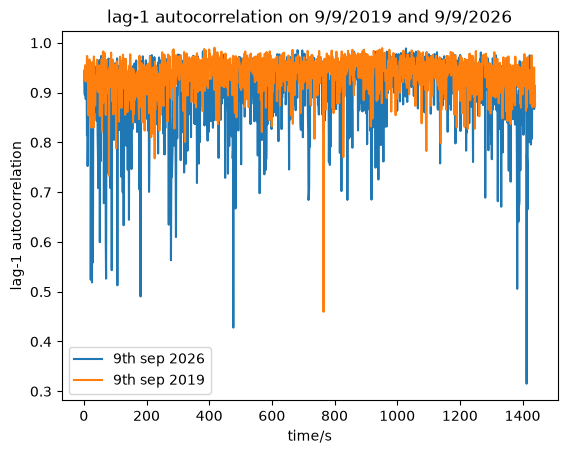

In [ ]:
#the datasets being used are recordings of the frequencies of the national grid over a month
#the lag-1 autocorrelation is just the pearson correlation coefficient between 
def get_lag_1(location: str, day): #function takes the location of the csv file in your computer as an argument, as well as the day of the month you want to analyse
    #this function will return the lag-1 autocorrelation for each minute
    data = pd.read_csv(location) #converts the csv to a usable format in python

    freqs = torch.tensor(data["f"].to_numpy())[(day-1)*3600*24:(day)*3600*24] #this extracts the frequency data for a particular day and stores it 
    #in a torch.tensor object, which is just a wrapper around an array that makes it easier to do statistical operations

    f_mins= einops.rearrange(freqs, "(d l) -> d l", l=60) 
    #this rearranges the data from a 1d array of frequencies into a 2d array. it goes from [24hrs of data] to [[1 min of data][1 min of data] ... [1 min of data]]. each individual sub array has length 60 and there are 60*24 of them. 

    f_mean = f_mins.mean(dim=-1, keepdim=True)
    #this calculates the mean frequency over each minute of the day

    f_centred = f_mins - f_mean 
    #this calculates the frequency - the mean frequency for each frequency in f_mins

    numerator = (f_centred[:, 1:] * f_centred[:, :-1]).sum(dim=-1)
    # this computes the numerator of the expression for lag-1 autocorrelation

    denominator = f_centred.square().sum(dim=-1)
    #this computes the denominator in the expression for lag 1 autocorrelation
    return numerator / denominator 

data2026 = get_lag_1("../data/fnew-2026-9.csv", 9) #produces an array containing lag-1 correlation for each minute on the 9th sept 2026
data2019Blackout = get_lag_1("../data/f 2019 8.csv", 9)

plt.plot([x for x in range(1, len(data2026)+1)], data2026, label="9th sep 2026")
plt.plot([x for x in range(1, len(data2019Blackout)+1)], data2019Blackout, label="9th sep 2019")
plt.title("lag-1 autocorrelation on 9/9/2019 and 9/9/2026")
plt.xlabel("time/s")
plt.ylabel("lag-1 autocorrelation")
plt.legend()
plt.show()